# Detección de fibrilación auricular en ECG de cuidados intensivos

Este cuaderno reproduce los clasificadores basados en rasgos de Nassar et al. (arXiv:2512.18031), del grupo de P. Abolmaesumi y P. Mousavi, y amplía el análisis con la transformada wavelet, la transformada de Radón, el análisis espectral, el límite de Cramér Rao y explicaciones SHAP.

El cuaderno sigue este orden:

1. Datos y etiquetas.
2. Preprocesamiento y detección de picos R.
3. Reproducción de las configuraciones 2 y 3 del artículo.
4. Ampliación con wavelet, Radón, espectro y Cramér Rao.
5. Estudio de ablación con intervalos de confianza.
6. Explicabilidad con SHAP.

La extracción de rasgos es costosa (unos 71 000 registros), por eso se ejecuta antes con scripts/extraer_rasgos.py y aquí solo se cargan sus resultados.

In [1]:
import os, sys, ast, warnings, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import scipy.signal as ss
import pywt, wfdb, joblib
from skimage.transform import radon

warnings.filterwarnings('ignore')
RAIZ = os.path.abspath('.')
sys.path.insert(0, os.path.join(RAIZ, 'scripts'))
import rasgos as R

DATA = os.path.join(RAIZ, 'data')
FIG = os.path.join(RAIZ, 'informe', 'figuras'); os.makedirs(FIG, exist_ok=True)
SEMILLA = 0
plt.rcParams.update({'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white',
                     'figure.dpi': 110, 'font.size': 10, 'axes.grid': True, 'grid.alpha': 0.3})
def guardar(fig, nombre):
    fig.savefig(os.path.join(FIG, nombre), dpi=200, bbox_inches='tight')

## 1. Datos

Se usan dos conjuntos de datos.

1. **Kingston ICU AF** (PhysioNet, acceso restringido): 596 ECG de 10 s de pacientes distintos, con las derivaciones I, II, III y un equivalente de V1 muestreadas a 240 Hz. Las clases son ritmo sinusal y fibrilación o aleteo auricular. El archivo metadata.csv trae la partición en mitades de entrenamiento y prueba que usa el artículo.
2. **PhysioNet/CinC 2021** (acceso abierto): ECG de 12 derivaciones de varias instituciones. Chapman/Shaoxing, Ningbo y PTB XL se descargan del espejo abierto de PhysioNet en AWS; CPSC 2018 y Georgia, de physionet.org. Se conservan las derivaciones I, II, III y V1.

Las etiquetas SNOMED de ritmo sinusal, bradicardia, taquicardia y arritmia sinusal forman la clase 0; fibrilación, aleteo, fibrilación con aleteo, fibrilación crónica y fibrilación rápida forman la clase 1. Se descartan los registros con ambas clases o con etiquetas que no existen en la UCI (marcapasos, bigeminia, trigeminia, arritmias ventriculares y otras taquicardias o bradicardias).

In [2]:
pub = pd.read_csv(os.path.join(DATA, 'etiquetas_publicas.csv'))
tabla2_articulo = pd.DataFrame({'ECG (artículo)': [41331, 2687, 5623, 20722], 'Prevalencia FA (artículo)': [0.22, 0.53, 0.12, 0.07]},
                               index=['Chapman/Shaoxing & Ningbo', 'CPSC_2018 & CPSC_2018_Extra', 'Georgia', 'PTB & PTB-XL'])
t2 = pub.groupby('fuente')['AF'].agg(['count', 'mean']).rename(columns={'count': 'ECG (este trabajo)', 'mean': 'Prevalencia FA (este trabajo)'})
t2 = t2.join(tabla2_articulo, how='outer').round(3)
t2.loc['Total'] = [len(pub), pub.AF.mean().round(3), 70363, 0.18]
t2

,ECG (este trabajo),Prevalencia FA (este trabajo),ECG (artículo),Prevalencia FA (artículo)
CPSC_2018 & CPSC_2018_Extra,2701.0,0.530,2687.0,0.53
Chapman/Shaoxing & Ningbo,42316.0,0.214,41331.0,0.22
Georgia,5610.0,0.120,5623.0,0.12
PTB & PTB-XL,20521.0,0.076,20722.0,0.07
Total,71148.0,0.179,70363.0,0.18


El etiquetado propio recupera casi el mismo número de registros que el artículo y la misma prevalencia de fibrilación por fuente. Las fuentes son muy desiguales: CPSC está balanceado, mientras que PTB casi no contiene fibrilación. Por eso el modelo de la configuración 3 aprende sobre una mezcla de poblaciones cuya prevalencia global, cercana al 18 %, se parece a la de la prueba de Kingston (16 %), aunque la población, los equipos y el ruido son distintos.

In [3]:
KIN = 'kingston-icu-af-dataset-1.0.0'
kin = pd.read_csv(os.path.join(DATA, KIN, 'metadata.csv'))
kin_lab = pd.DataFrame({'registro': KIN + '/' + kin.ECG, 'AF': (kin.Rhythm != 'SINUS').astype(int),
                        'particion': kin.TrainOrTest.str.lower()})
pd.crosstab(kin.Rhythm, kin.TrainOrTest, margins=True)

TrainOrTest,Test,Train,All
Rhythm,,,
AFIB/AFLT,49,50,99
SINUS,249,248,497
All,298,298,596


Las dos mitades de Kingston tienen la misma proporción de fibrilación. Con solo 49 casos positivos en la prueba, cada error de clasificación cambia F1 en uno o dos puntos, y esa granularidad debe tenerse en cuenta al comparar modelos.

## 2. Preprocesamiento y detección de picos R

El artículo aplica un filtro Butterworth pasabanda de orden 2 entre 5 y 30 Hz en ambos sentidos (filtfilt), lo que anula el desfase y duplica el orden efectivo. Las señales públicas, muestreadas a 500 Hz, se remuestrean a 240 Hz con un filtro polifásico. Los picos R se detectan con SleepECG, que usa umbrales adaptativos. Si una derivación tiene tres picos o menos, el registro se descarta.

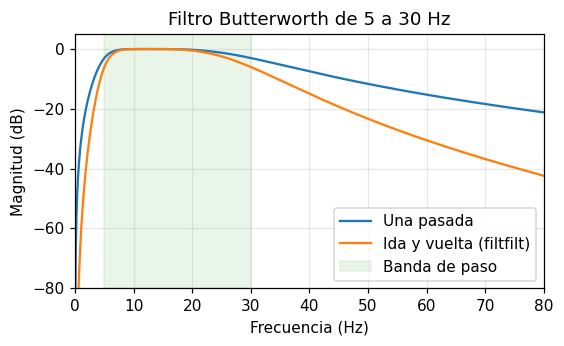

In [4]:
fs_ej = 500
b, a = ss.butter(2, [5, 30], btype='bandpass', fs=fs_ej)
w, h = ss.freqz(b, a, worN=4096, fs=fs_ej)
fig, ax = plt.subplots(1, 1, figsize=(5.5, 3))
ax.plot(w, 20*np.log10(np.abs(h) + 1e-12), label='Una pasada')
ax.plot(w, 40*np.log10(np.abs(h) + 1e-12), label='Ida y vuelta (filtfilt)')
ax.axvspan(5, 30, color='tab:green', alpha=0.1, label='Banda de paso')
ax.set(xlim=(0, 80), ylim=(-80, 5), xlabel='Frecuencia (Hz)', ylabel='Magnitud (dB)', title='Filtro Butterworth de 5 a 30 Hz')
ax.legend(); guardar(fig, 'fig_filtro.png'); plt.show()

El filtrado en ambos sentidos eleva la magnitud al cuadrado: la atenuación fuera de la banda se duplica en decibelios y la fase resultante es nula, de modo que los picos R no se desplazan. El precio es que la banda de 5 a 30 Hz elimina gran parte de la energía de la onda P y de la línea de base, algo que conviene recordar al interpretar el rasgo de amplitud de la onda P.

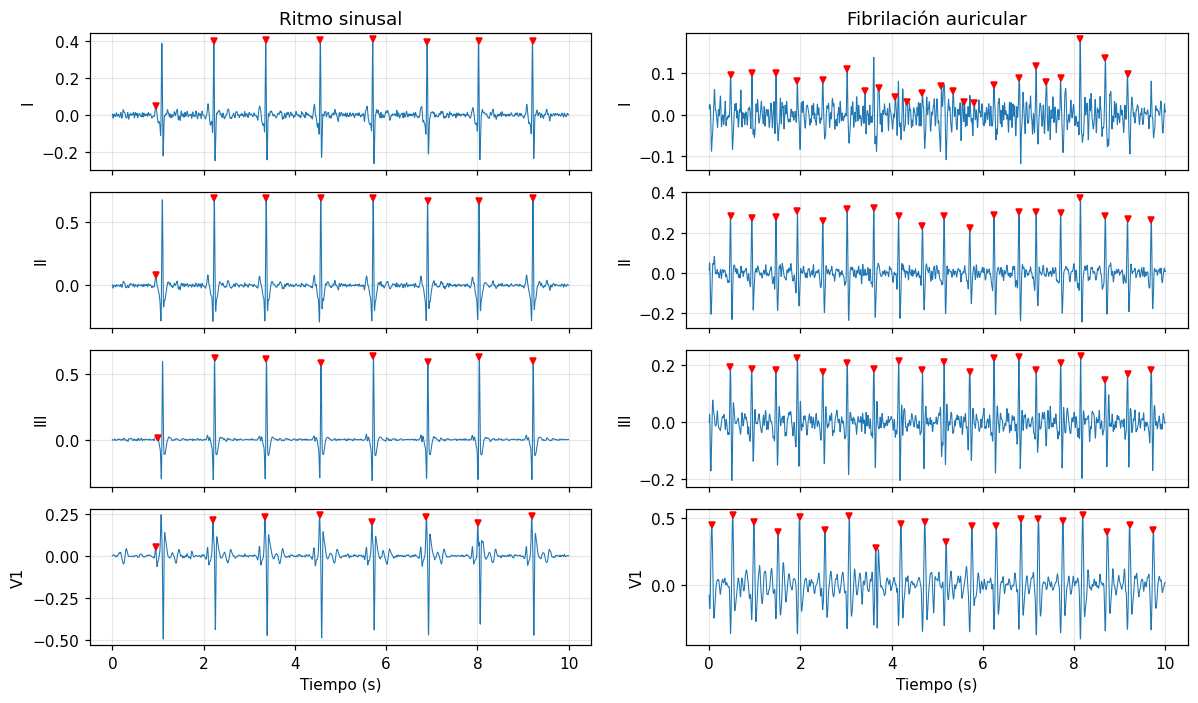

In [5]:
def leer4(reg):
    rec = wfdb.rdrecord(os.path.join(DATA, reg))
    idx = [rec.sig_name.index(l) for l in ['I', 'II', 'III']] + [rec.sig_name.index('V1') if 'V1' in rec.sig_name else 3]
    return rec.p_signal[:int(10*rec.fs), idx], rec.fs

ch = pub[pub.fuente.str.startswith('Chapman')]
reg_sr = ch[ch.AF == 0].registro.iloc[0]; reg_af = ch[ch.AF == 1].registro.iloc[0]
ejemplos = {}
fig, axs = plt.subplots(4, 2, figsize=(11, 6.5), sharex=True)
for j, (nom, reg) in enumerate([('Ritmo sinusal', reg_sr), ('Fibrilación auricular', reg_af)]):
    sig, fs = leer4(reg); xf = R.preprocesar(sig.T, fs); ejemplos[nom] = (sig, fs, xf)
    t = np.arange(xf.shape[1]) / R.FS
    for i, l in enumerate(R.LEADS):
        r = R.picos_r(xf[i])
        axs[i, j].plot(t, xf[i], lw=0.7); axs[i, j].plot(r/R.FS, xf[i][r], 'rv', ms=4)
        axs[i, j].set_ylabel(l)
    axs[0, j].set_title(nom); axs[-1, j].set_xlabel('Tiempo (s)')
fig.tight_layout(); guardar(fig, 'fig_ejemplos_ecg.png'); plt.show()

SleepECG marca los picos R de forma consistente en las cuatro derivaciones, incluso en V1, donde el QRS es pequeño. En ritmo sinusal los picos aparecen a intervalos casi constantes; en fibrilación los intervalos RR son irregulares y entre latidos la línea de base oscila sin ondas P definidas. Los rasgos del artículo miden justamente esta irregularidad.

## 3. Rasgos del artículo base

Por derivación se calculan 27 rasgos con NeuroKit2 (Tabla I del artículo): calidad de la señal, frecuencia cardiaca, estadísticos de los intervalos RR (mínimo, máximo, media, mediana, desviación estándar, desviación absoluta mediana, rango intercuartílico y percentiles 20 y 80), SDSD, pNN20, pNN50, índice triangular, rasgos del diagrama de Poincaré (SD1, SD2, área y las seis contribuciones de aceleraciones y desaceleraciones), fragmentación (PIP), entropía de Shannon y amplitud media de la onda P. Con cuatro derivaciones resultan 108 columnas.

In [6]:
import experimentos as E
from experimentos import BASE_COLS, GRUPOS, CONJ, MODELOS, MOD_AB, cols_de
Xp, tr, te = E.cargar_datos()
yte = te.AF.values
fp = E.leer_rasgos('rasgos_publicos.csv'); fk = E.leer_rasgos('rasgos_kingston.csv')
pd.DataFrame({'Públicos': fp.estado.value_counts(), 'Kingston': fk.estado.value_counts()}).fillna(0).astype(int)

,Públicos,Kingston
estado,,
derivacion_plana,883,0
ok,70203,596
pocos_picos,43,0


Todos los registros de Kingston producen rasgos válidos. En los datos públicos se pierde poco más del 1 %, casi siempre por una derivación plana (electrodo desconectado) y muy rara vez por falta de picos. El conjunto de entrenamiento final queda muy cerca de los 70 363 registros del artículo.

## 4. Reproducción

Se entrenan los ocho clasificadores del artículo con sus parámetros por omisión y 1000 estimadores en los conjuntos de árboles. La única diferencia es que en la configuración 3 la SVM se entrena con una submuestra estratificada de 20 000 registros, porque su costo crece casi con el cuadrado del número de muestras. Antes del entrenamiento los rasgos se imputan con la mediana del entrenamiento y se escalan al intervalo [0, 1]. El umbral de decisión es 0,5. Todas las métricas se calculan sobre la mitad de prueba de Kingston (n = 298).

1. **Configuración 2:** entrenamiento con la mitad de entrenamiento de Kingston (n = 298).
2. **Configuración 3:** entrenamiento con los datos públicos de PhysioNet 2021.

In [7]:
from sklearn import metrics as M
print('Kingston entrenamiento:', len(tr), 'con', tr.AF.sum(), 'FA | prueba:', len(te), 'con', yte.sum(), 'FA | públicos:', len(Xp))

Kingston entrenamiento: 298 con 50 FA | prueba: 298 con 49 FA | públicos: 70203


In [8]:
ART = {  # Tablas S2 y S3 del artículo: AUROC, AUPRC, F1, MCC
 'conf2': {'KNN': (.95,.82,.83,.79), 'MLP': (.96,.91,.83,.80), 'SVM': (.97,.89,.81,.77), 'LR': (.97,.88,.80,.76),
           'RF': (.96,.89,.78,.75), 'LightGBM': (.97,.92,.81,.77), 'XGBoost': (.97,.90,.82,.79), 'CatBoost': (.97,.91,.83,.79)},
 'conf3': {'KNN': (.90,.74,.81,.77), 'MLP': (.93,.82,.79,.76), 'SVM': (.93,.87,.84,.81), 'LR': (.97,.88,.81,.77),
           'RF': (.93,.86,.76,.72), 'LightGBM': (.93,.86,.78,.74), 'XGBoost': (.94,.86,.78,.74), 'CatBoost': (.94,.87,.77,.72)}}
correr = lambda conf, conjunto, nombres: E.correr(conf, conjunto, nombres, Xp, tr, te)

def comparar(res, conf):
    art = pd.DataFrame(ART[conf], index=['AUROC', 'AUPRC', 'F1', 'MCC']).T
    return pd.concat({'Artículo': art, 'Reproducido': res[['AUROC', 'AUPRC', 'F1', 'MCC']]}, axis=1).round(2)

In [9]:
res2, pred2 = correr('conf2', 'Base', MODELOS)
comparar(res2, 'conf2')

Artículo                   Reproducido                  
            AUROC AUPRC    F1   MCC       AUROC AUPRC    F1   MCC
KNN          0.95  0.82  0.83  0.79        0.94  0.80  0.82  0.79
MLP          0.96  0.91  0.83  0.80        0.94  0.88  0.78  0.74
SVM          0.97  0.89  0.81  0.77        0.96  0.89  0.81  0.78
LR           0.97  0.88  0.80  0.76        0.97  0.89  0.79  0.75
RF           0.96  0.89  0.78  0.75        0.96  0.89  0.79  0.76
LightGBM     0.97  0.92  0.81  0.77        0.97  0.91  0.83  0.80
XGBoost      0.97  0.90  0.82  0.79        0.96  0.89  0.84  0.81
CatBoost     0.97  0.91  0.83  0.79        0.97  0.91  0.84  0.80

In [10]:
res3, pred3 = correr('conf3', 'Base', MODELOS)
comparar(res3, 'conf3')

Artículo                   Reproducido                  
            AUROC AUPRC    F1   MCC       AUROC AUPRC    F1   MCC
KNN          0.90  0.74  0.81  0.77        0.91  0.76  0.77  0.72
MLP          0.93  0.82  0.79  0.76        0.92  0.83  0.80  0.77
SVM          0.93  0.87  0.84  0.81        0.92  0.86  0.82  0.79
LR           0.97  0.88  0.81  0.77        0.97  0.90  0.82  0.79
RF           0.93  0.86  0.76  0.72        0.93  0.87  0.78  0.75
LightGBM     0.93  0.86  0.78  0.74        0.93  0.86  0.82  0.79
XGBoost      0.94  0.86  0.78  0.74        0.93  0.86  0.78  0.73
CatBoost     0.94  0.87  0.77  0.72        0.93  0.85  0.76  0.71

La reproducción es fiel en ambas configuraciones. En la configuración 2 las diferencias con el artículo caen dentro de un par de errores de clasificación, salvo el MLP, que depende de la inicialización aleatoria y de un conjunto de entrenamiento muy pequeño. En la configuración 3 se repite el patrón central del artículo: la regresión logística conserva su AUROC al cambiar de dominio, mientras que los modelos de árboles y los vecinos pierden entre tres y cuatro puntos. Un modelo lineal sobre rasgos escalados extrapola mejor a una población nueva que un modelo que memoriza particiones finas del espacio de rasgos.

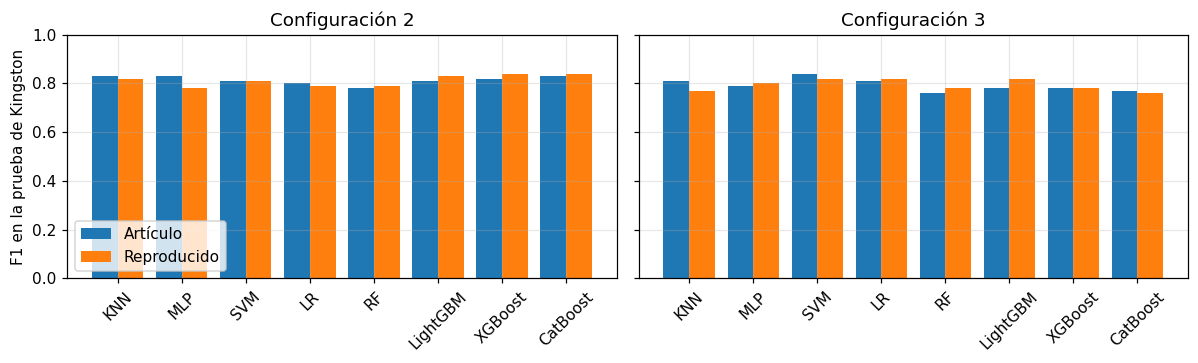

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, conf, res in [(axs[0], 'conf2', res2), (axs[1], 'conf3', res3)]:
    c = comparar(res, conf); x = np.arange(len(c))
    ax.bar(x - 0.2, c[('Artículo', 'F1')], 0.4, label='Artículo')
    ax.bar(x + 0.2, c[('Reproducido', 'F1')], 0.4, label='Reproducido')
    ax.set_xticks(x, c.index, rotation=45); ax.set_ylim(0, 1)
    ax.set_title('Configuración 2' if conf == 'conf2' else 'Configuración 3')
axs[0].set_ylabel('F1 en la prueba de Kingston'); axs[0].legend(loc='lower left')
fig.tight_layout(); guardar(fig, 'fig_f1_reproduccion.png'); plt.show()

Las barras confirman que ningún modelo se aleja del artículo de forma sistemática y que el orden relativo de los modelos es inestable. Con 49 fibrilaciones en la prueba, F1 no basta para declarar un ganador; las curvas completas y los intervalos de confianza de la sección 6 son más informativos.

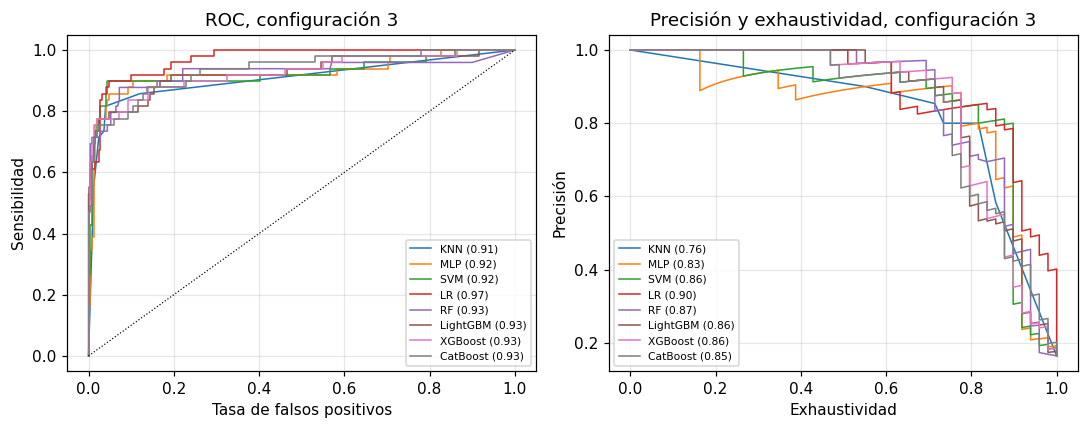

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for n, p in pred3.items():
    f, t, _ = M.roc_curve(yte, p); axs[0].plot(f, t, lw=1, label=f'{n} ({M.roc_auc_score(yte, p):.2f})')
    pr, rc, _ = M.precision_recall_curve(yte, p); axs[1].plot(rc, pr, lw=1, label=f'{n} ({M.average_precision_score(yte, p):.2f})')
axs[0].plot([0, 1], [0, 1], 'k:', lw=0.8)
axs[0].set(xlabel='Tasa de falsos positivos', ylabel='Sensibilidad', title='ROC, configuración 3')
axs[1].set(xlabel='Exhaustividad', ylabel='Precisión', title='Precisión y exhaustividad, configuración 3')
axs[0].legend(fontsize=7); axs[1].legend(fontsize=7)
fig.tight_layout(); guardar(fig, 'fig_roc_pr_conf3.png'); plt.show()

Todas las curvas ROC suben casi en vertical: cerca del 80 % de las fibrilaciones se detectan con muy pocas falsas alarmas. Las diferencias aparecen en el último 20 %, los casos difíciles, donde la regresión logística alcanza la sensibilidad completa antes que el resto. La curva de precisión y exhaustividad lo muestra con más claridad, porque no se diluye en la gran mayoría de ritmos sinusales: la precisión cae bruscamente por encima del 80 % de exhaustividad en todos los modelos. Ese grupo de fibrilaciones difíciles es el que la ampliación debería ayudar a separar.

## 5. Ampliación del análisis

### 5.1 Transformada wavelet

La transformada wavelet continua con la wavelet de Morlet da un escalograma tiempo y escala. En ritmo sinusal los complejos QRS forman columnas regulares de energía en las escalas pequeñas y la onda P aparece como energía de baja frecuencia antes de cada QRS. En fibrilación las columnas pierden regularidad y la banda de 4 a 9 Hz muestra actividad continua.

La transformada wavelet discreta con db4 y cinco niveles divide la señal de 240 Hz en las bandas A5 (0 a 3,75 Hz), D5 (3,75 a 7,5 Hz), D4 (7,5 a 15 Hz), D3 (15 a 30 Hz), D2 y D1. Se usan como rasgos la energía relativa de cada banda y la entropía wavelet. Sobre la serie RR se aplica la transformada de Haar vista en clase: la energía relativa de los detalles mide la variación entre latidos consecutivos.

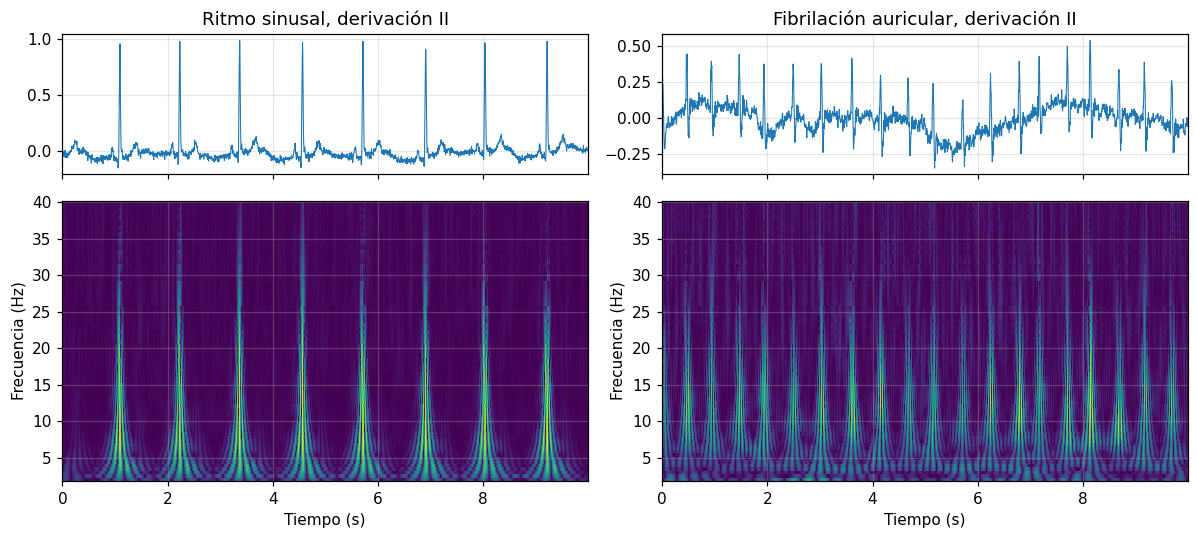

In [13]:
fig, axs = plt.subplots(2, 2, figsize=(11, 5), gridspec_kw={'height_ratios': [1, 2]}, sharex='col')
frecs = np.linspace(2, 40, 80)
escalas = pywt.central_frequency('morl') * R.FS / frecs
for j, nom in enumerate(ejemplos):
    sig, fs, xf = ejemplos[nom]
    x = ss.resample_poly(sig[:, 1], R.FS, int(fs)); x = x - x.mean()
    coef, _ = pywt.cwt(x, escalas, 'morl', sampling_period=1/R.FS)
    t = np.arange(len(x)) / R.FS
    axs[0, j].plot(t, x, lw=0.7); axs[0, j].set_title(f'{nom}, derivación II')
    axs[1, j].pcolormesh(t, frecs, np.abs(coef), shading='auto', cmap='viridis')
    axs[1, j].set(xlabel='Tiempo (s)', ylabel='Frecuencia (Hz)')
fig.tight_layout(); guardar(fig, 'fig_escalogramas.png'); plt.show()

En ritmo sinusal el escalograma es un tren de columnas equiespaciadas, una por QRS, que se ensanchan hacia las frecuencias bajas por la peor resolución temporal de las escalas grandes. En fibrilación las columnas se acercan y se separan de forma irregular, y la franja inferior a 8 Hz conserva energía entre latidos, que corresponde a las ondas fibrilatorias. La wavelet separa así en un solo mapa las dos firmas de la arritmia: la irregularidad ventricular y la actividad auricular desorganizada.

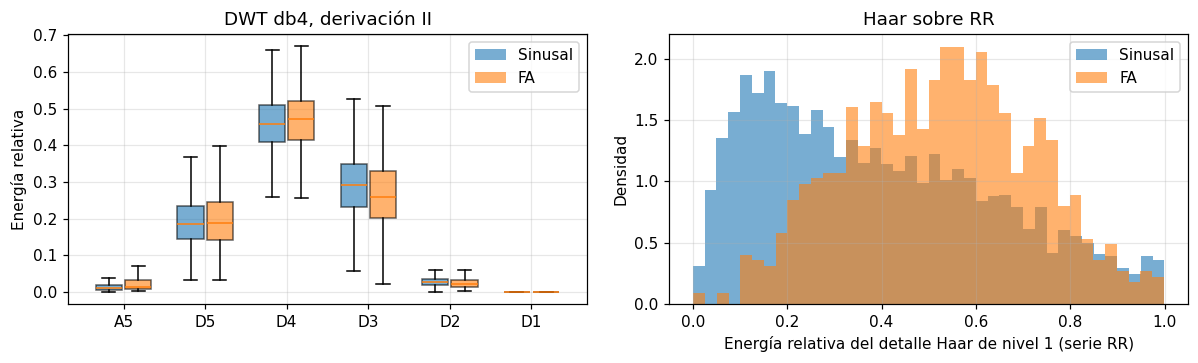

In [14]:
cols_dwt = [f'II_DWT_E{b}' for b in ['A5', 'D5', 'D4', 'D3', 'D2', 'D1']]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
d = Xp.sample(min(5000, len(Xp)), random_state=SEMILLA)
pos = np.arange(len(cols_dwt))
for c, (lab, off) in enumerate([(0, -0.18), (1, 0.18)]):
    axs[0].boxplot([d.loc[d.AF == lab, k].dropna() for k in cols_dwt], positions=pos + off, widths=0.32,
                   showfliers=False, patch_artist=True, boxprops=dict(facecolor=f'C{c}', alpha=0.6))
axs[0].set_xticks(pos, [k.split('_E')[1] for k in cols_dwt]); axs[0].set(ylabel='Energía relativa', title='DWT db4, derivación II')
axs[0].legend([plt.Rectangle((0, 0), 1, 1, fc='C0', alpha=0.6), plt.Rectangle((0, 0), 1, 1, fc='C1', alpha=0.6)], ['Sinusal', 'FA'])
for lab, nom in [(0, 'Sinusal'), (1, 'FA')]:
    axs[1].hist(d.loc[d.AF == lab, 'II_HaarRR_Ed1'].dropna(), bins=40, alpha=0.6, density=True, label=nom)
axs[1].set(xlabel='Energía relativa del detalle Haar de nivel 1 (serie RR)', ylabel='Densidad', title='Haar sobre RR'); axs[1].legend()
fig.tight_layout(); guardar(fig, 'fig_wavelet_rasgos.png'); plt.show()

Las energías relativas de la DWT en la derivación II apenas difieren entre clases: el filtro de 5 a 30 Hz ya recortó las bandas donde vive la onda fibrilatoria, y la energía queda dominada por el QRS en D4 y D3. La transformada de Haar sobre la serie RR desplaza más las distribuciones: en ritmo sinusal la energía del detalle de nivel 1 es baja porque latidos consecutivos se parecen, mientras que en fibrilación la mayor parte de la energía pasa al detalle porque cada intervalo difiere del anterior. Aun así, el solapamiento es grande y por sí sola discrimina menos que pNN50, porque al normalizar por la energía total pierde la escala absoluta de la variabilidad, que es lo que más distingue a la fibrilación.

### 5.2 Transformada de Radón

La transformada de Radón proyecta una imagen sobre rectas con ángulo $\theta$:

$$\mathcal{R}f(\rho, \theta) = \int\int f(x, y)\,\delta(x\cos\theta + y\sin\theta - \rho)\,dx\,dy.$$

Se aplica al diagrama de recurrencia $RP_{ij} = \Theta(\varepsilon - \lVert \mathbf{v}_i - \mathbf{v}_j \rVert)$, donde $\mathbf{v}_i = (x_i, x_{i+\tau}, x_{i+2\tau})$ es el embebido de retardo de la derivación filtrada y $\varepsilon$ fija una tasa de recurrencia del 10 %. Un ritmo periódico genera líneas paralelas a la diagonal principal, y su proyección a 45 grados concentra la energía en pocos valores de $\rho$. En fibrilación esas líneas se fragmentan. Los rasgos son la varianza de la proyección a 45 grados, su cociente con la varianza media de todos los ángulos, el ángulo de máxima varianza y la curtosis de la proyección a 45 grados.

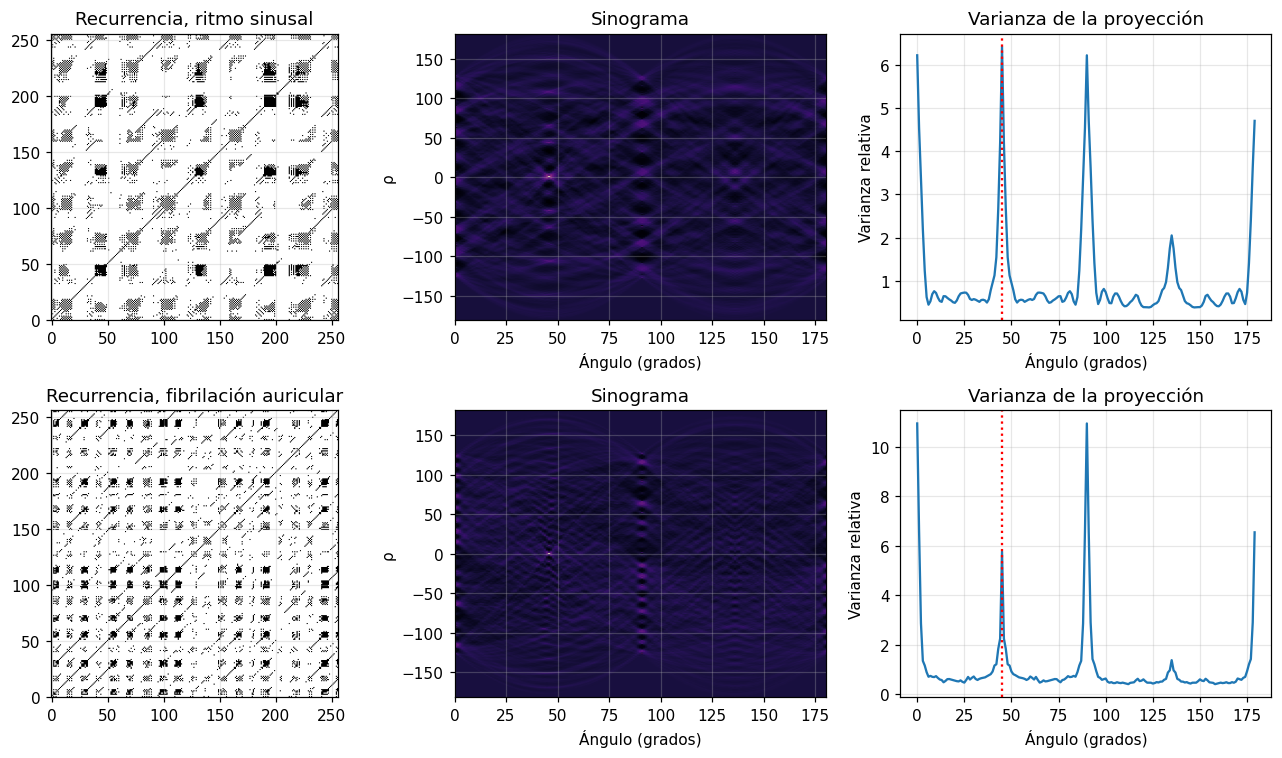

In [15]:
fig, axs = plt.subplots(2, 3, figsize=(12, 7))
ang = np.arange(0, 180, 1)
for i, nom in enumerate(ejemplos):
    xf = ejemplos[nom][2][1]
    rp = R.recurrence_plot(xf)
    s = radon(rp - rp.mean(), theta=ang, circle=False)
    axs[i, 0].imshow(rp, cmap='binary', origin='lower'); axs[i, 0].set_title(f'Recurrencia, {nom.lower()}')
    axs[i, 1].imshow(s, aspect='auto', cmap='magma', extent=(0, 180, -s.shape[0]/2, s.shape[0]/2))
    axs[i, 1].set(xlabel='Ángulo (grados)', ylabel='ρ', title='Sinograma')
    axs[i, 2].plot(ang, s.var(axis=0) / s.var(axis=0).mean()); axs[i, 2].axvline(45, color='r', ls=':')
    axs[i, 2].set(xlabel='Ángulo (grados)', ylabel='Varianza relativa', title='Varianza de la proyección')
fig.tight_layout(); guardar(fig, 'fig_radon.png'); plt.show()

El diagrama de recurrencia del ritmo sinusal muestra bloques que se repiten con el periodo cardiaco y diagonales paralelas a la principal: el sistema vuelve una y otra vez al mismo estado. En fibrilación las diagonales son cortas y su espaciado es irregular. En el sinograma esto se traduce en que la proyección a 45 grados, la dirección de las diagonales, pierde peso frente a las de 0 y 90 grados, que solo reflejan la estructura en bloques común a ambas clases. La transformada de Radón convierte así una propiedad dinámica, el determinismo del ritmo, en un perfil angular fácil de resumir.

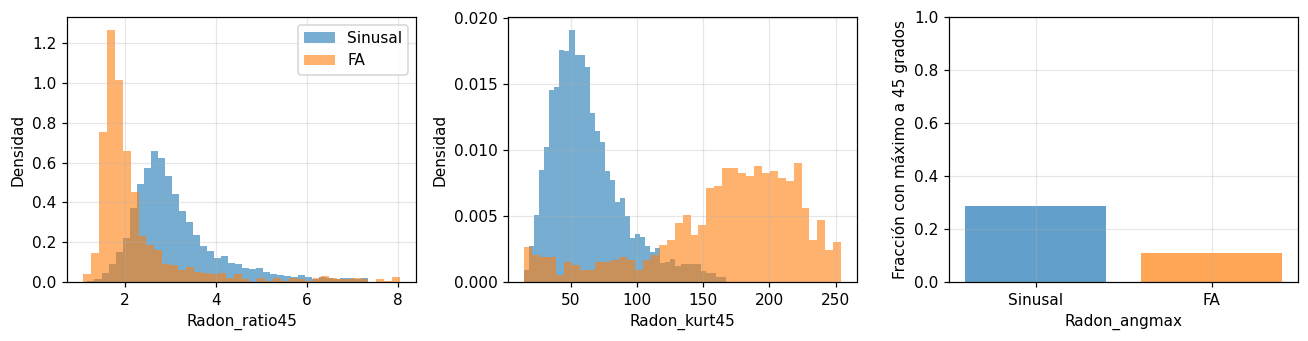

In [16]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, k in zip(axs[:2], ['II_Radon_ratio45', 'II_Radon_kurt45']):
    for lab, nom in [(0, 'Sinusal'), (1, 'FA')]:
        v = d.loc[d.AF == lab, k].dropna(); v = v[v < v.quantile(0.99)]
        ax.hist(v, bins=40, alpha=0.6, density=True, label=nom)
    ax.set(xlabel=k.replace('II_', ''), ylabel='Densidad')
prop = d.groupby('AF')['II_Radon_angmax'].apply(lambda v: (v == 45).mean())
axs[2].bar(['Sinusal', 'FA'], prop.values, color=['C0', 'C1'], alpha=0.7)
axs[2].set(ylabel='Fracción con máximo a 45 grados', xlabel='Radon_angmax', ylim=(0, 1))
axs[0].legend(); fig.tight_layout(); guardar(fig, 'fig_radon_rasgos.png'); plt.show()

Los rasgos de Radón separan las clases mejor que cualquier rasgo wavelet; la curtosis a 45 grados es, por sí sola, el rasgo más discriminante de los 172, por encima de pNN50, en ambos dominios. En fibrilación el cociente a 45 grados es menor, y la curtosis de esa proyección es mucho mayor porque solo sobrevive la diagonal principal, que produce un pico aislado en lugar de varios picos repartidos. El ángulo de máxima varianza es un rasgo más tosco, pero también informativo: el máximo cae a 45 grados con mucha mayor frecuencia en ritmo sinusal.

### 5.3 Análisis espectral de la actividad auricular

Para aislar la actividad auricular se resta de cada latido una plantilla promedio del complejo QRST, alineada en los picos R, y se estima la densidad espectral con el método de Welch. En fibrilación las ondas fibrilatorias concentran la potencia entre 4 y 9 Hz. Los rasgos son la frecuencia dominante entre 3 y 12 Hz, el índice de organización (potencia a menos de 0,5 Hz de la frecuencia dominante dividida por la potencia de la banda) y la entropía espectral normalizada.

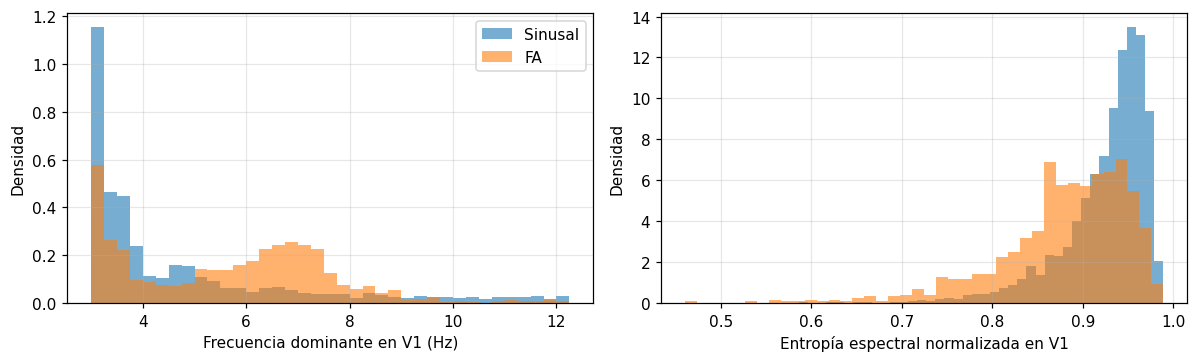

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
for lab, nom in [(0, 'Sinusal'), (1, 'FA')]:
    axs[0].hist(d.loc[d.AF == lab, 'V1_Spec_DF'].dropna(), bins=np.arange(3, 12.5, 0.25), alpha=0.6, density=True, label=nom)
    axs[1].hist(d.loc[d.AF == lab, 'V1_Spec_Hent'].dropna(), bins=40, alpha=0.6, density=True, label=nom)
axs[0].set(xlabel='Frecuencia dominante en V1 (Hz)', ylabel='Densidad'); axs[1].set(xlabel='Entropía espectral normalizada en V1', ylabel='Densidad')
axs[0].legend(); fig.tight_layout(); guardar(fig, 'fig_espectro.png'); plt.show()

Tras restar el QRST, el residuo de V1 en ritmo sinusal tiene su máximo en el borde inferior de la banda, donde queda energía de la onda T mal cancelada. En fibrilación aparece un modo claro entre 5 y 8 Hz, que equivale a 300 a 480 activaciones auriculares por minuto y coincide con la frecuencia fibrilatoria descrita en la literatura clínica. La entropía espectral es menor en fibrilación, lo que parece contradictorio con la idea de desorden, pero tiene sentido: la onda fibrilatoria concentra la potencia en un pico, mientras que el residuo sinusal es casi ruido blanco. El efecto es más fuerte en V1, la derivación más cercana a las aurículas.

### 5.4 Límite de Cramér Rao para la frecuencia cardiaca

En ritmo sinusal los instantes de los picos R siguen el modelo lineal

$$t_k = t_0 + kT + w_k, \quad k = 0, \dots, K-1, \quad w_k \sim \mathcal{N}(0, \sigma^2),$$

donde $T$ es el periodo cardiaco y $w_k$ es el error de detección. Es el mismo problema de recta con dos parámetros visto en clase. La matriz de Fisher de $(t_0, T)$ es

$$\mathbf{I} = \frac{1}{\sigma^2}\begin{bmatrix} K & \sum k \\ \sum k & \sum k^2 \end{bmatrix},$$

y al invertirla se obtiene

$$\mathrm{var}(\hat T) \geq \frac{12\,\sigma^2}{K(K^2-1)}.$$

Como la frecuencia cardiaca es $FC = 60/T$, por la propiedad de transformación del límite se cumple que

$$\mathrm{var}(\widehat{FC}) \geq \left(\frac{60}{T^2}\right)^2 \frac{12\,\sigma^2}{K(K^2-1)}.$$

El estimador de mínimos cuadrados es eficiente en este modelo. Para comprobarlo se simula un ECG sintético de 10 s a 240 Hz, construido como suma de gaussianas para las ondas P, Q, R, S y T. A cada latido se le suma un desplazamiento gaussiano independiente de desviación conocida, con ruido blanco de 20 dB, y se repite 400 veces por nivel. Los picos se detectan con SleepECG y se ajusta la recta. El límite se calcula con $\sigma^2$ igual a la varianza del desplazamiento más la de cuantización, $\Delta^2/12$ con $\Delta = 1/240$ s.

,sigma (ms),var FC empírica,CRLB FC,eficiencia
0,1,0.00014,0.00013,0.96496
1,2,0.00029,0.00030,1.02294
2,5,0.00152,0.00146,0.96080
3,10,0.00528,0.00560,1.06012
4,20,0.02145,0.02215,1.03257
5,40,0.33986,0.08834,0.25993


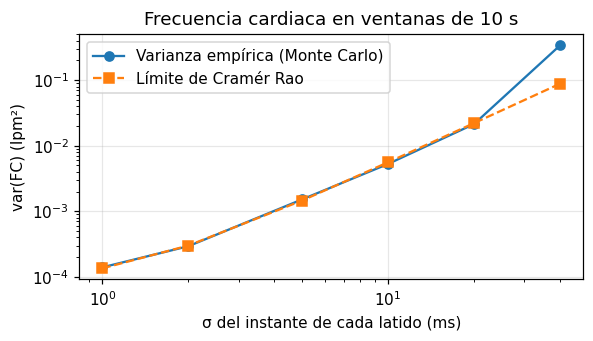

In [18]:
rng = np.random.default_rng(SEMILLA)
FC0 = 73; T0 = 60 / FC0; DUR = 10
ONDAS = [(0.15, -0.20, 0.025), (-0.10, -0.025, 0.008), (1.0, 0.0, 0.010), (-0.20, 0.025, 0.008), (0.30, 0.25, 0.050)]
def ecg_sintetico(centros, fs=R.FS):
    # ECG sintético en tiempo continuo: suma de gaussianas P, Q, R, S y T centradas en cada latido
    t = np.arange(int(DUR*fs)) / fs
    x = np.zeros_like(t)
    for c in centros:
        for a, mu, sd in ONDAS:
            x += a * np.exp(-0.5*((t - c - mu)/sd)**2)
    return x

b5, a5 = ss.butter(2, [5, 30], btype='bandpass', fs=R.FS)
k_all = np.arange(-1, DUR/T0 + 1)
SNR = 20
filas = []
for sj in [1, 2, 5, 10, 20, 40]:                    # desviación del desplazamiento de cada latido (ms)
    est, Skks = [], []
    for _ in range(400):
        c = rng.uniform(0, T0) + k_all*T0 + rng.normal(0, sj/1000, len(k_all))
        x0 = ecg_sintetico(c)
        x = x0 + rng.normal(0, np.sqrt(np.mean(x0**2) / 10**(SNR/10)), len(x0))
        r = R.picos_r(ss.filtfilt(b5, a5, x))
        if len(r) < 4: continue
        tk = r / R.FS
        k = np.round((tk - tk[0]) / np.median(np.diff(tk)))      # índice de latido robusto a latidos perdidos
        ok = np.r_[True, np.diff(k) > 0]; tk, k = tk[ok], k[ok]
        A = np.c_[np.ones_like(k), k]; th, *_ = np.linalg.lstsq(A, tk, rcond=None)
        est.append(60/th[1]); Skks.append(np.sum((k - k.mean())**2))
    s2 = (sj/1000)**2 + (1/R.FS)**2/12               # desplazamiento más cuantización uniforme
    crlb = (60/T0**2)**2 * s2 / np.median(Skks)      # 12σ²/(K(K²−1)) = σ²/Σ(k − k̄)²
    filas.append({'sigma (ms)': sj, 'var FC empírica': np.var(est), 'CRLB FC': crlb})
crlb_df = pd.DataFrame(filas); crlb_df['eficiencia'] = crlb_df['CRLB FC'] / crlb_df['var FC empírica']
display(crlb_df.round(5))
fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.loglog(crlb_df['sigma (ms)'], crlb_df['var FC empírica'], 'o-', label='Varianza empírica (Monte Carlo)')
ax.loglog(crlb_df['sigma (ms)'], crlb_df['CRLB FC'], 's--', label='Límite de Cramér Rao')
ax.set(xlabel='σ del instante de cada latido (ms)', ylabel='var(FC) (lpm²)', title='Frecuencia cardiaca en ventanas de 10 s'); ax.legend()
fig.tight_layout(); guardar(fig, 'fig_crlb.png'); plt.show()

Hasta 20 ms de dispersión la varianza del estimador de mínimos cuadrados coincide con el límite de Cramér Rao: el estimador es eficiente y el error de la frecuencia cardiaca en 10 s es despreciable para la clínica. A 40 ms aparece el efecto umbral: la dispersión es comparable al ancho del QRS, el detector empieza a perder latidos o a asignar mal el índice de latido, y la varianza se separa del límite, que solo es válido en la región de error pequeño. La lección para este problema es que con 10 s de registro la frecuencia media se estima casi sin error y la información útil está en la irregularidad, que es justamente lo que miden los rasgos de variabilidad.

## 6. Estudio de ablación

Se comparan cinco conjuntos de rasgos: los 27 del artículo por derivación, los mismos más wavelet, más Radón, más espectro y todos juntos. Se usan tres modelos representativos (regresión logística, k vecinos y CatBoost) en ambas configuraciones. Los intervalos de confianza del 95 % de F1 y AUROC se obtienen con 1000 remuestreos bootstrap de la prueba de Kingston.

In [19]:
filas, PRED = [], {}
for conf in ['conf2', 'conf3']:
    for nom in CONJ:
        r_, p_ = correr(conf, nom, MOD_AB)
        for m in MOD_AB:
            PRED[(conf, nom, m)] = p_[m]
            ci_f1, ci_au = E.bootstrap(yte, p_[m])
            filas.append({'Configuración': conf[-1], 'Rasgos': nom, 'Modelo': m, 'F1': r_.loc[m, 'F1'],
                          'F1 inf': ci_f1[0], 'F1 sup': ci_f1[1], 'AUROC': r_.loc[m, 'AUROC'],
                          'AUROC inf': ci_au[0], 'AUROC sup': ci_au[1], 'MCC': r_.loc[m, 'MCC']})
abl = pd.DataFrame(filas)
abl.pivot_table(index=['Configuración', 'Rasgos'], columns='Modelo', values=['F1', 'AUROC']).round(3)

AUROC                     F1              
Modelo                        CatBoost    KNN     LR CatBoost    KNN     LR
Configuración Rasgos                                                       
2             Base               0.969  0.940  0.971    0.837  0.824  0.787
              Base + Espectro    0.968  0.940  0.973    0.833  0.828  0.833
              Base + Radón       0.966  0.942  0.975    0.773  0.843  0.817
              Base + Wavelet     0.971  0.935  0.967    0.821  0.835  0.787
              Todos              0.970  0.950  0.973    0.800  0.863  0.813
3             Base               0.935  0.907  0.971    0.755  0.766  0.821
              Base + Espectro    0.938  0.909  0.967    0.774  0.787  0.826
              Base + Radón       0.943  0.910  0.957    0.812  0.742  0.831
              Base + Wavelet     0.937  0.920  0.967    0.776  0.825  0.809
              Todos              0.959  0.932  0.959    0.804  0.800  0.805

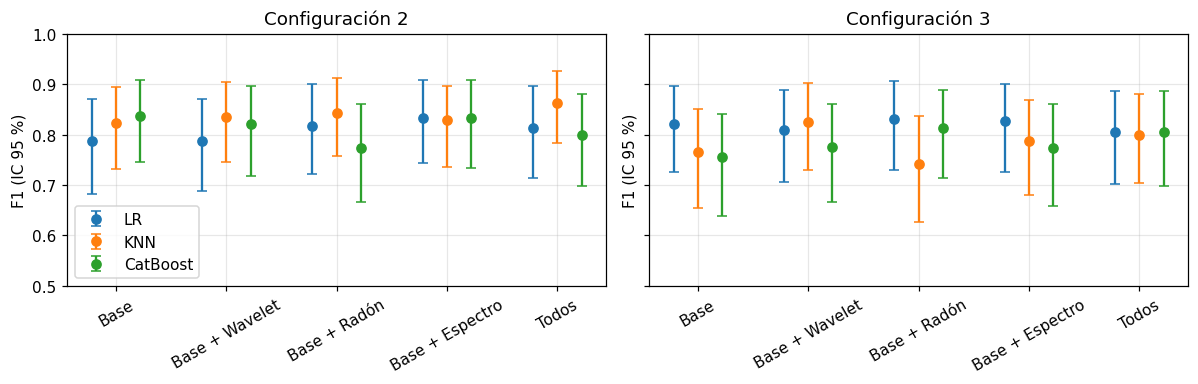

In [20]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, c in zip(axs, ['2', '3']):
    t = abl[abl.Configuración == c]
    x = np.arange(len(CONJ))
    for k, m in enumerate(MOD_AB):
        u = t[t.Modelo == m].set_index('Rasgos').loc[list(CONJ)]
        ax.errorbar(x + (k - 1)*0.22, u.F1, yerr=[u.F1 - u['F1 inf'], u['F1 sup'] - u.F1], fmt='o', capsize=3, label=m)
    ax.set_xticks(x, list(CONJ), rotation=30); ax.set(title=f'Configuración {c}', ylabel='F1 (IC 95 %)', ylim=(0.5, 1))
axs[0].legend()
fig.tight_layout(); guardar(fig, 'fig_ablacion.png'); plt.show()

Ningún conjunto ampliado mejora F1 de forma significativa: los intervalos de confianza se solapan en todos los casos y miden unos quince puntos de ancho, el reflejo directo de tener solo 49 fibrilaciones en la prueba. Dentro de Kingston (configuración 2) los rasgos base ya están cerca del techo y añadir columnas a 298 registros apenas cambia nada. El cambio de dominio (configuración 3) es más revelador: con todos los rasgos, CatBoost y los vecinos recuperan buena parte del AUROC que habían perdido frente a la regresión logística, mientras que esta no gana nada. En la comparación pareada por bootstrap, el intervalo de la diferencia de AUROC excluye el cero para CatBoost y para los vecinos, aunque por poco y sin corregir por las 24 comparaciones del estudio. Los rasgos de Radón y espectro describen la fisiología de la arritmia y no las particularidades de cada base de datos, por lo que se trasladan mejor de una población a otra.

## 7. Explicabilidad con SHAP

Los valores SHAP reparten la salida del modelo entre los rasgos según el valor de Shapley de la teoría de juegos cooperativos. Para modelos de árboles TreeSHAP los calcula de forma exacta. Se aplican al modelo CatBoost de la configuración 3 con todos los rasgos y se evalúan en la prueba de Kingston. Se muestran la importancia global y dos explicaciones locales: un falso positivo y un falso negativo.

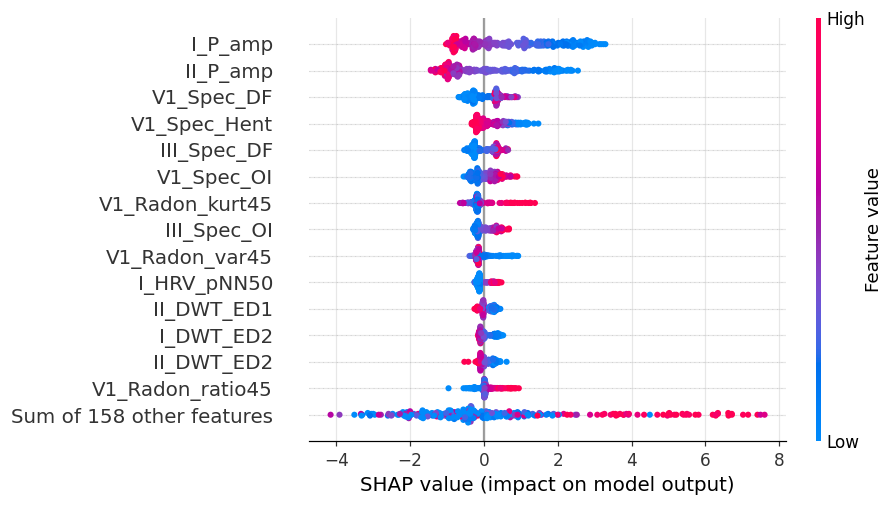

Importancia SHAP por grupo de rasgos:
Base        6.225
Espectro    1.975
Wavelet     1.390
Radón       1.271
dtype: float64


In [21]:
import shap
pipe = joblib.load(os.path.join(E.RES, 'modelo_conf3_todo.joblib'))
cols = CONJ['Todos'][1]
Xte_t = pd.DataFrame(pipe[:-1].transform(te[cols]), columns=cols)
expl = shap.TreeExplainer(pipe[-1]); sv = expl(Xte_t)
plt.figure(); shap.plots.beeswarm(sv, max_display=15, show=False)
plt.gcf().set_size_inches(7, 5); guardar(plt.gcf(), 'fig_shap_global.png'); plt.show()
imp = pd.Series(np.abs(sv.values).mean(0), index=cols).sort_values(ascending=False)
grupo = lambda c: 'Wavelet' if any(g in c for g in GRUPOS['Wavelet']) else 'Radón' if 'Radon' in c else 'Espectro' if 'Spec' in c else 'Base'
print('Importancia SHAP por grupo de rasgos:'); print(imp.groupby(imp.index.map(grupo)).sum().sort_values(ascending=False).round(3))

El rasgo más importante no mide el ritmo, sino la amplitud de la onda P en las derivaciones I y II: cuando es baja, el modelo empuja con fuerza hacia la fibrilación, que es exactamente el criterio clínico de ausencia de ondas P. Le siguen la frecuencia dominante, la entropía y el índice de organización espectral de V1 y III, y la curtosis de Radón en V1, todos con la dirección fisiológica esperada. Los rasgos clásicos de variabilidad RR aparecen menos arriba de lo que cabría esperar porque son muchos y muy correlacionados entre sí, y su importancia se reparte. Por grupos, los 27 rasgos base por derivación aportan algo más de la mitad de la importancia y los 16 ampliados, que son minoría, aportan el resto.

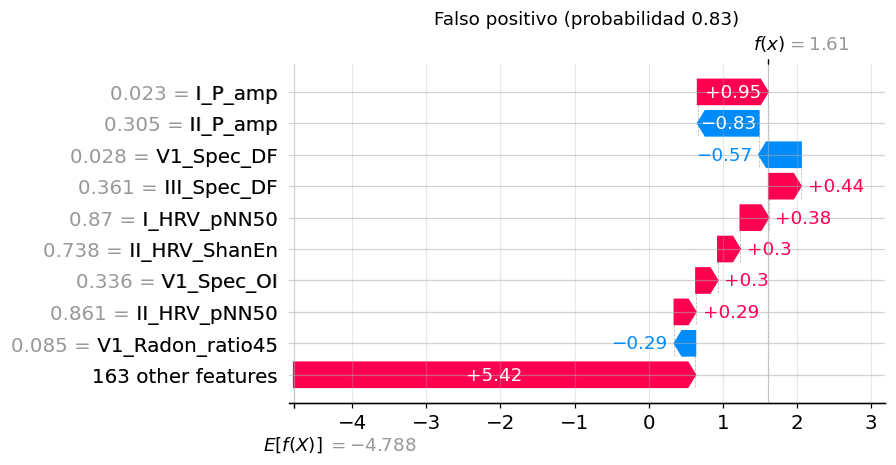

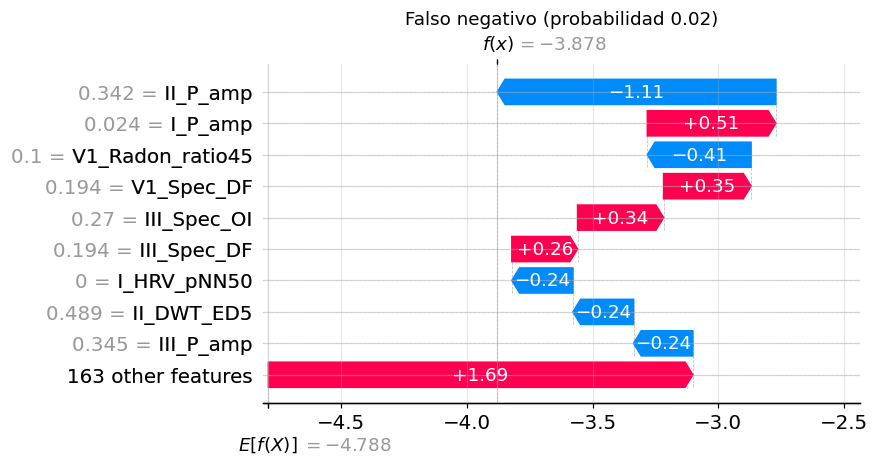

In [22]:
p = PRED[('conf3', 'Todos', 'CatBoost')]; yh = (p >= 0.5).astype(int)
casos = {'Falso positivo': np.where((yh == 1) & (yte == 0))[0], 'Falso negativo': np.where((yh == 0) & (yte == 1))[0]}
for nom, idx in casos.items():
    if len(idx) == 0: print(nom, ': no hay casos'); continue
    i = idx[np.argmax(np.abs(p[idx] - 0.5))]
    plt.figure(); shap.plots.waterfall(sv[i], max_display=10, show=False)
    plt.title(f'{nom} (probabilidad {p[i]:.2f})'); plt.gcf().set_size_inches(7, 4)
    guardar(plt.gcf(), f'fig_shap_{nom.split()[1].lower()}.png'); plt.show()

El falso positivo más confiado es un ritmo sinusal con onda P casi ausente en la derivación I y con intervalos RR muy variables (pNN50 alto y entropía de Shannon elevada), un perfil compatible con arritmia sinusal o extrasístoles frecuentes. La onda P visible en II y la falta de un pico fibrilatorio en V1 empujan en contra, pero no alcanzan. El falso negativo más confiado es el caso opuesto: una fibrilación con onda P aparente en II y III y con intervalos RR regulares (pNN50 nulo), lo que sugiere un aleteo auricular con conducción fija, que el artículo agrupa con la fibrilación aunque su ritmo ventricular sea regular. En ambos errores el modelo razona como un clínico con información incompleta, y las explicaciones señalan qué falta: una mejor detección de la onda P y rasgos específicos del aleteo.

## 8. Conclusiones

1. **Reproducción.** Los ocho clasificadores basados en rasgos reproducen las métricas del artículo en ambas configuraciones con diferencias del orden de uno o dos errores de clasificación. También se repite su hallazgo principal: la regresión logística es el modelo más robusto al pasar de los datos públicos a la UCI.
2. **Wavelet.** El escalograma muestra a la vez la irregularidad ventricular y la actividad auricular continua. Como rasgo, la energía Haar de la serie RR separa las clases solo de forma parcial, y las energías DWT de la señal filtrada aportan poco porque el filtro de 5 a 30 Hz ya eliminó gran parte de la onda fibrilatoria.
3. **Radón.** Proyectar el diagrama de recurrencia resume el determinismo del ritmo en pocos números; la curtosis a 45 grados es uno de los rasgos ampliados más discriminantes y más usados por el modelo.
4. **Espectro.** Tras cancelar el QRST, V1 revela la frecuencia fibrilatoria entre 5 y 8 Hz, en acuerdo con la fisiología. Es el grupo ampliado con mayor importancia SHAP.
5. **Cramér Rao.** La frecuencia cardiaca media de 10 s se estima de forma eficiente hasta dispersiones de 20 ms, con el umbral de error esperado por encima; la información diagnóstica está en la irregularidad y no en la frecuencia media.
6. **Ablación.** Los rasgos ampliados no cambian F1 de forma significativa con esta prueba, pero en el cambio de dominio acercan el AUROC de los modelos no lineales al de la regresión logística, con una mejora pequeña cuyo intervalo pareado excluye el cero, lo que apunta a una mejor transferencia.
7. **Explicabilidad.** SHAP muestra que el modelo se apoya en la ausencia de onda P y en la actividad auricular, y no solo en la irregularidad RR. La amplitud de la onda P discrimina mucho mejor en los datos públicos que en Kingston, lo que ayuda a explicar por qué CatBoost, que la usa como rasgo principal, pierde más que la regresión logística al cambiar de dominio. Los errores corresponden a ritmos sinusales irregulares y a fibrilaciones o aleteos con respuesta ventricular regular, lo que indica dónde mejorar.

La principal limitación es el tamaño de la prueba de Kingston: con 49 fibrilaciones los intervalos de confianza de F1 son anchos y las diferencias entre conjuntos de rasgos deben confirmarse con validación cruzada o con más datos de UCI.